# Dataset exploration — Synthetic SMOA & truth 50 bang

Notebook mô tả dữ liệu trước khi train/backtest. Các câu hỏi:
1. Có bao nhiêu curve, quan sát và nhóm synthetic? Độ dài và scale khác nhau thế nào?
2. Truth có cùng lịch quan sát không? Có giá trị âm, số 0, missing hoặc trùng tuần không?
3. Hình dạng và độ lớn khác nhau thế nào giữa các bang và synthetic families?
4. Các đặc điểm này ảnh hưởng gì tới embedding và cách đọc điểm benchmark?

Chỉ đọc CSV gốc; không impute, sửa hoặc xóa quan sát. Đây là phân tích mô tả
trên toàn bộ dữ liệu, không dùng để chọn hyperparameter theo kết quả test.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "experiments/synthetic/generator.py").exists())
sys.path.insert(0, str(ROOT / "experiments/exploration"))
from explore_datasets import (load_inputs, summarize_synthetic, summarize_truth,
                             truth_anomalies, largest_changes, run_exploration)
SYNTHETIC = ROOT / "outputs/synthetic_demo/curves.csv"
MANIFEST = ROOT / "outputs/truth_states/manifest.csv"
OUT = ROOT / "outputs/dataset_exploration"
K, H = 5, 4
print("Input: synthetic_demo + truth_states. Output:", OUT.relative_to(ROOT))

Input: synthetic_demo + truth_states. Output: outputs/dataset_exploration


## 1. Đọc dữ liệu và schema
`step` là bước trong cadence gốc, chưa phải ngày lịch. Truth là final truth dùng để chấm điểm.

In [2]:
synthetic, truth, sources = load_inputs(SYNTHETIC, MANIFEST)
display(pd.DataFrame({"dataset": ["synthetic", "truth"],
                      "rows": [len(synthetic), len(truth)],
                      "series": [synthetic.curve_id.nunique(), truth.series.nunique()]}))
display(synthetic.head())
display(truth.head())

,dataset,rows,series
0,synthetic,8641,30
1,truth,7267,50


,curve_id,seed,curve_type,time_cadence,scale,seasonal,step,value
0,1,1,sir_rollercoaster,weekly,counts,False,1,1.000000e-10
1,1,1,sir_rollercoaster,weekly,counts,False,2,1.000000e-10
2,1,1,sir_rollercoaster,weekly,counts,False,3,1.000000e-10
3,1,1,sir_rollercoaster,weekly,counts,False,4,1.000000e-10
4,1,1,sir_rollercoaster,weekly,counts,False,5,1.000000e-10


,target_end_date,value,series,source_file
0,2020-01-25,0.0,Alabama,Alabama.csv
1,2020-02-01,0.0,Alabama,Alabama.csv
2,2020-02-08,0.0,Alabama,Alabama.csv
3,2020-02-15,0.0,Alabama,Alabama.csv
4,2020-02-22,0.0,Alabama,Alabama.csv


## 2. Synthetic: nhóm, độ dài và phân phối
Thống kê từng curve; phân biệt scale/cadence. Giá trị `1e-10` phản ánh floor của generator, không phải dữ liệu thiếu.

In [3]:
synstats = summarize_synthetic(synthetic, K, H)
display(synstats.groupby(["curve_type", "scale", "time_cadence"]).agg(
    curves=("curve_id", "size"), median_steps=("observations", "median"),
    floor_values=("floor_values", "sum"), embedding_windows=("embedding_windows", "sum")))
display(synstats[["observations", "min_value", "median_value", "max_value"]].describe())
print("Cửa sổ sau kiểm tra variance, k=5, h=4:", synstats.embedding_windows.sum())
print("Curve sai step sequence:", (~synstats.step_sequence_valid).sum())
print("Curve có metadata không nhất quán:", (~synstats.metadata_consistent).sum())

curves  median_steps  \
curve_type               scale      time_cadence                         
seasonal                 counts     monthly            2         124.0   
                                    weekly             2         182.0   
                         proportion monthly            4         137.0   
                                    weekly             2         442.0   
sir_rollercoaster        counts     weekly             5         271.0   
                         proportion weekly             5         254.0   
sir_rollercoaster_wiggle counts     weekly             5         248.0   
                         proportion weekly             5         377.0   

                                                  floor_values  \
curve_type               scale      time_cadence                 
seasonal                 counts     monthly                 19   
                                    weekly                 204   
                         proportion monthly                 56   
                                    weekly                 315   
sir_rollercoaster        counts     weekly                 270   
                         proportion weekly                 317   
sir_rollercoaster_wiggle counts     weekly                 177   
                         proportion weekly                 572   

                                                  embedding_windows  
curve_type               scale      time_cadence                     
seasonal                 counts     monthly                     230  
                                    weekly                      346  
                         proportion monthly                     473  
                                    weekly                      866  
sir_rollercoaster        counts     weekly                     1384  
                         proportion weekly                     1553  
sir_rollercoaster_wiggle counts     weekly                     1381  
                         proportion weekly                     2138

,observations,min_value,median_value,max_value
count,30.000000,3.000000e+01,3.000000e+01,3.000000e+01
mean,288.033333,3.232000e+02,3.126742e+04,1.096670e+06
std,147.571253,1.770239e+03,7.335166e+04,2.838614e+06
min,59.000000,1.000000e-10,1.000000e-10,5.602994e-04
25%,183.250000,1.000000e-10,9.294797e-05,8.396015e-03
50%,258.000000,1.000000e-10,7.667788e-04,4.082102e-02
75%,359.000000,1.000000e-10,4.772125e+03,4.705318e+05
max,701.000000,9.696000e+03,3.205420e+05,1.359486e+07


Cửa sổ sau kiểm tra variance, k=5, h=4: 8371
Curve sai step sequence: 0
Curve có metadata không nhất quán: 0


## 3. Truth: lịch quan sát và chất lượng dữ liệu
Giữ nguyên giá trị âm/số 0. Runner backtest có thể floor ở 1, nhưng EDA hiển thị raw trước xử lý.

In [4]:
truthstats = summarize_truth(truth)
display(truthstats.groupby(["first_date", "last_date"]).agg(
    states=("series", "size"), min_weeks=("observations", "min"), max_weeks=("observations", "max")))
display(truthstats[["series", "observations", "missing_values", "invalid_dates",
    "duplicate_date_rows", "nonweekly_intervals", "missing_week_slots", "negative_values", "zeros"]])

states  min_weeks  max_weeks
first_date last_date                               
2020-01-25 2022-10-29      49        145        145
           2023-02-25       1        162        162

,series,observations,missing_values,invalid_dates,duplicate_date_rows,nonweekly_intervals,missing_week_slots,negative_values,zeros
0,Alabama,145,0,0,0,0,0,0,7
1,Alaska,145,0,0,0,0,0,0,7
2,Arizona,162,0,0,0,0,0,0,5
3,Arkansas,145,0,0,0,0,0,0,7
4,California,145,0,0,0,0,0,0,1
5,Colorado,145,0,0,0,0,0,0,6
6,Connecticut,145,0,0,0,0,0,0,7
7,Delaware,145,0,0,0,0,0,1,7
8,Florida,145,0,0,0,0,0,1,15
9,Georgia,145,0,0,0,0,0,0,6


## 4. Giá trị bất thường và mức thay đổi lớn
Zero không tự động là lỗi. Thay đổi lớn có thể là sóng dịch hoặc thay đổi báo cáo; chỉ đánh dấu để kiểm tra, không tự gọi là outlier để loại bỏ.

In [5]:
anomalies = truth_anomalies(truth)
display(anomalies[anomalies.value < 0][["series", "target_end_date", "value", "flags"]])
print("Số 0 trong raw truth:", int((truth.value == 0).sum()))
print("Số giá trị sẽ thay đổi khi floor ở 1:", int((truth.value < 1).sum()))
display(largest_changes(truth)[["series", "target_end_date", "previous_value", "value", "change"]])

,series,target_end_date,value,flags
1147,Delaware,2022-04-09,-730.0,negative_value
1311,Florida,2022-08-20,-25117.0,negative_value
3561,Missouri,2021-04-17,-4584.0,negative_value
3900,Nebraska,2022-03-26,-15.0,negative_value
3931,Nebraska,2022-10-29,-6709.0,negative_value
4946,North Dakota,2022-10-29,-211.0,negative_value
6795,Washington,2022-02-19,-1343.0,negative_value
7238,Wyoming,2022-04-16,-23.0,negative_value


Số 0 trong raw truth: 324
Số giá trị sẽ thay đổi khi floor ở 1: 332


,series,target_end_date,previous_value,value,change
700,California,2022-01-15,541840.0,852280.0,310440.0
699,California,2022-01-08,233453.0,541840.0,308387.0
703,California,2022-02-05,595595.0,317545.0,-278050.0
4613,New York,2022-01-01,167569.0,415674.0,248105.0
6209,Texas,2022-01-08,142538.0,371815.0,229277.0
4616,New York,2022-01-22,403723.0,214490.0,-189233.0
1278,Florida,2022-01-01,124865.0,302179.0,177314.0
702,California,2022-01-29,769679.0,595595.0,-174084.0
1311,Florida,2022-08-20,124717.0,-25117.0,-149834.0
698,California,2022-01-01,89712.0,233453.0,143741.0


## 5. Xuất biểu đồ và báo cáo
Có thể chạy lại cell này: chỉ ghi các file dẫn xuất trong thư mục EDA, không thay đổi input. Plot scale normalized chỉ để mô tả; không phải preprocessing của forecast.

In [6]:
summary = run_exploration(SYNTHETIC, MANIFEST, OUT, K, H)
print(json.dumps(summary, indent=2))

{
  "synthetic": {
    "curves": 30,
    "observations": 8641,
    "families": {
      "sir_rollercoaster": 10,
      "sir_rollercoaster_wiggle": 10,
      "seasonal": 10
    },
    "cadence": {
      "weekly": 24,
      "monthly": 6
    },
    "scale": {
      "proportion": 16,
      "counts": 14
    },
    "floor_values": 1930,
    "embedding_windows": 8371,
    "k": 5,
    "h": 4,
    "nonfinite_values": 0,
    "invalid_step_sequences": 0,
    "inconsistent_metadata": 0
  },
  "truth": {
    "series": 50,
    "observations": 7267,
    "first_date": "2020-01-25",
    "last_date": "2023-02-25",
    "common_start": "2020-01-25",
    "common_end": "2022-10-29",
    "negative_values": 8,
    "series_with_negatives": 7,
    "zero_values": 324,
    "values_changed_by_floor_1": 332,
    "missing_values": 0,
    "invalid_dates": 0,
    "duplicate_date_rows": 0,
    "nonweekly_intervals": 0
  }
}


### Hình dạng từng nhóm synthetic
Mỗi curve chia cho peak riêng; tối đa 3 curve mỗi family/scale. Nhãn ghi cadence gốc; trục step không phải cùng một độ dài thời gian cho monthly và weekly.

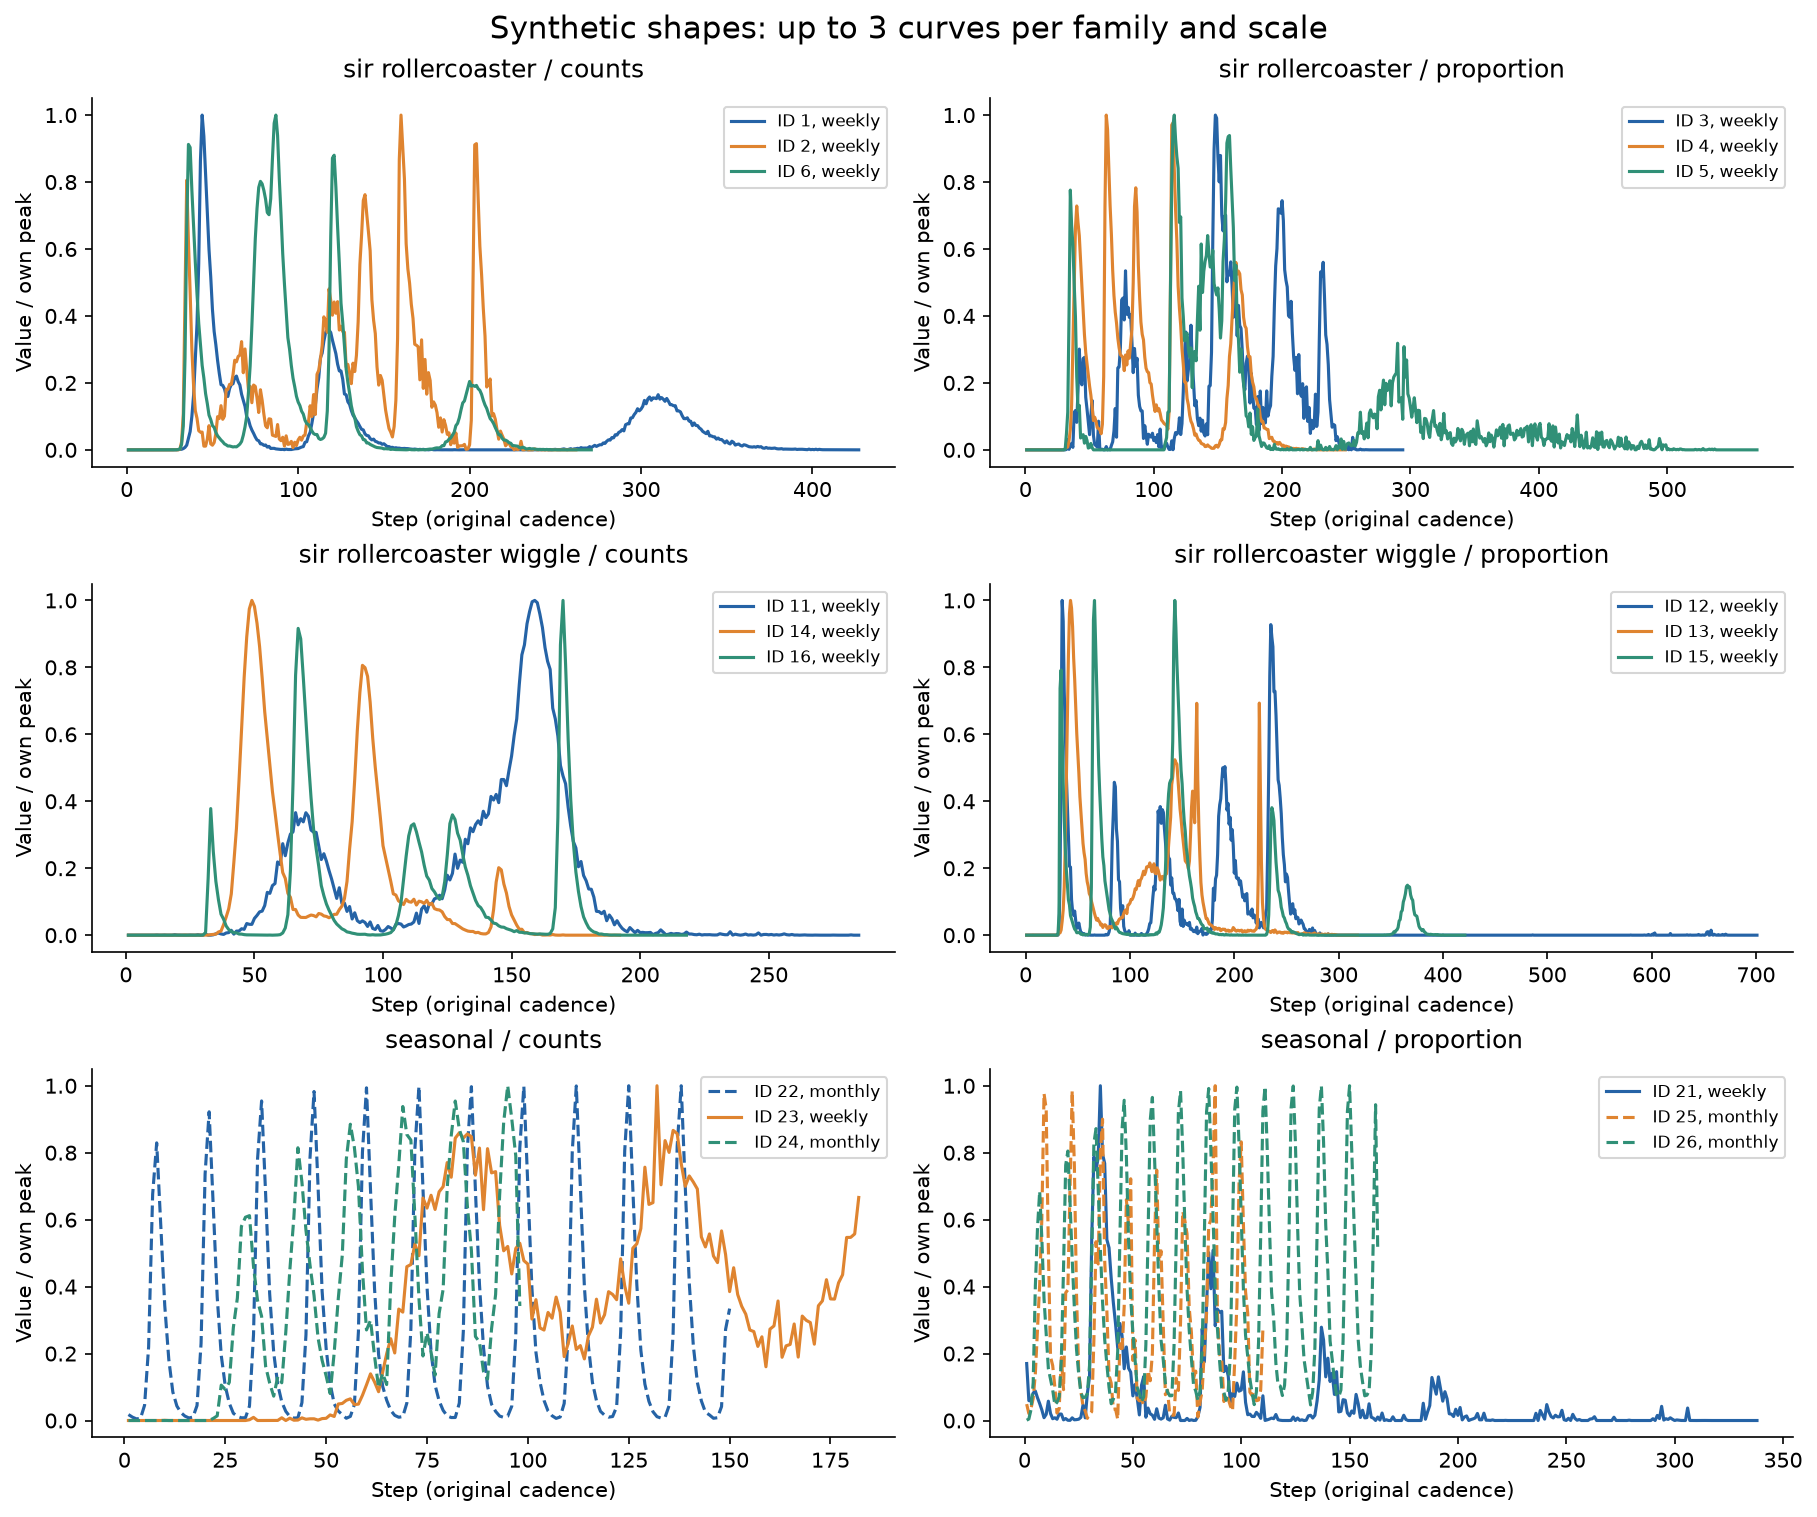

In [7]:
display(Image(filename=str(OUT / "figures/01_synthetic_examples.png")))

### Peak và độ dài synthetic
Peak counts và proportion được tách riêng; histogram dùng log10 peak. Các curve ngắn/dài tạo số cửa sổ training khác nhau.

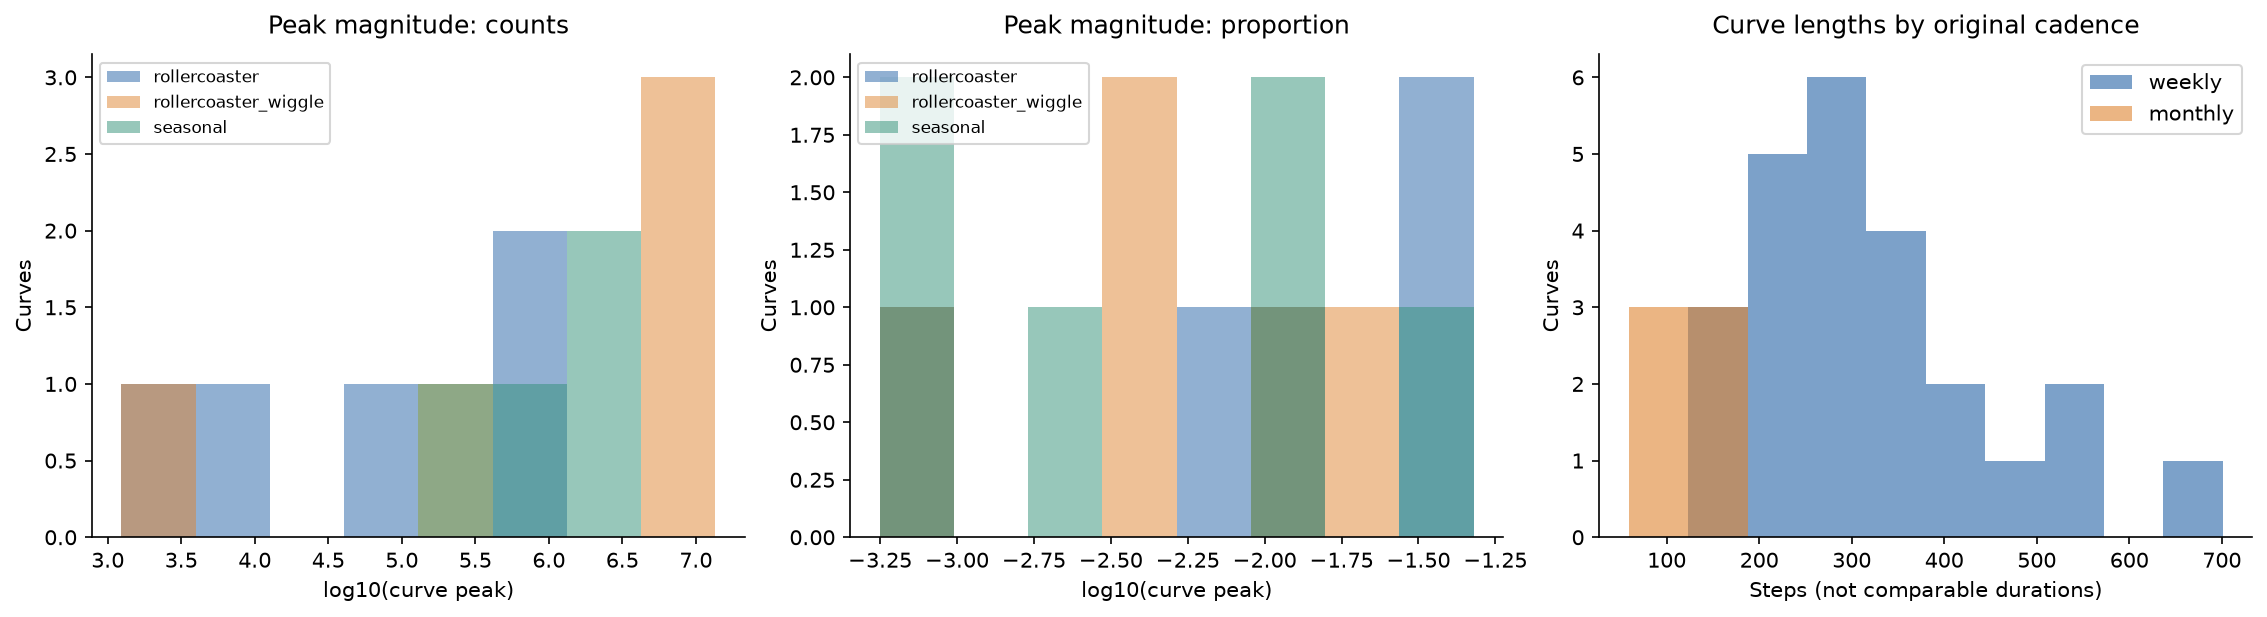

In [8]:
display(Image(filename=str(OUT / "figures/02_synthetic_distributions.png")))

### Lịch quan sát của 50 bang
Màu xanh là có dòng CSV tại tuần đó, không khẳng định giá trị hợp lệ; bảng audit phía trên kiểm tra giá trị.

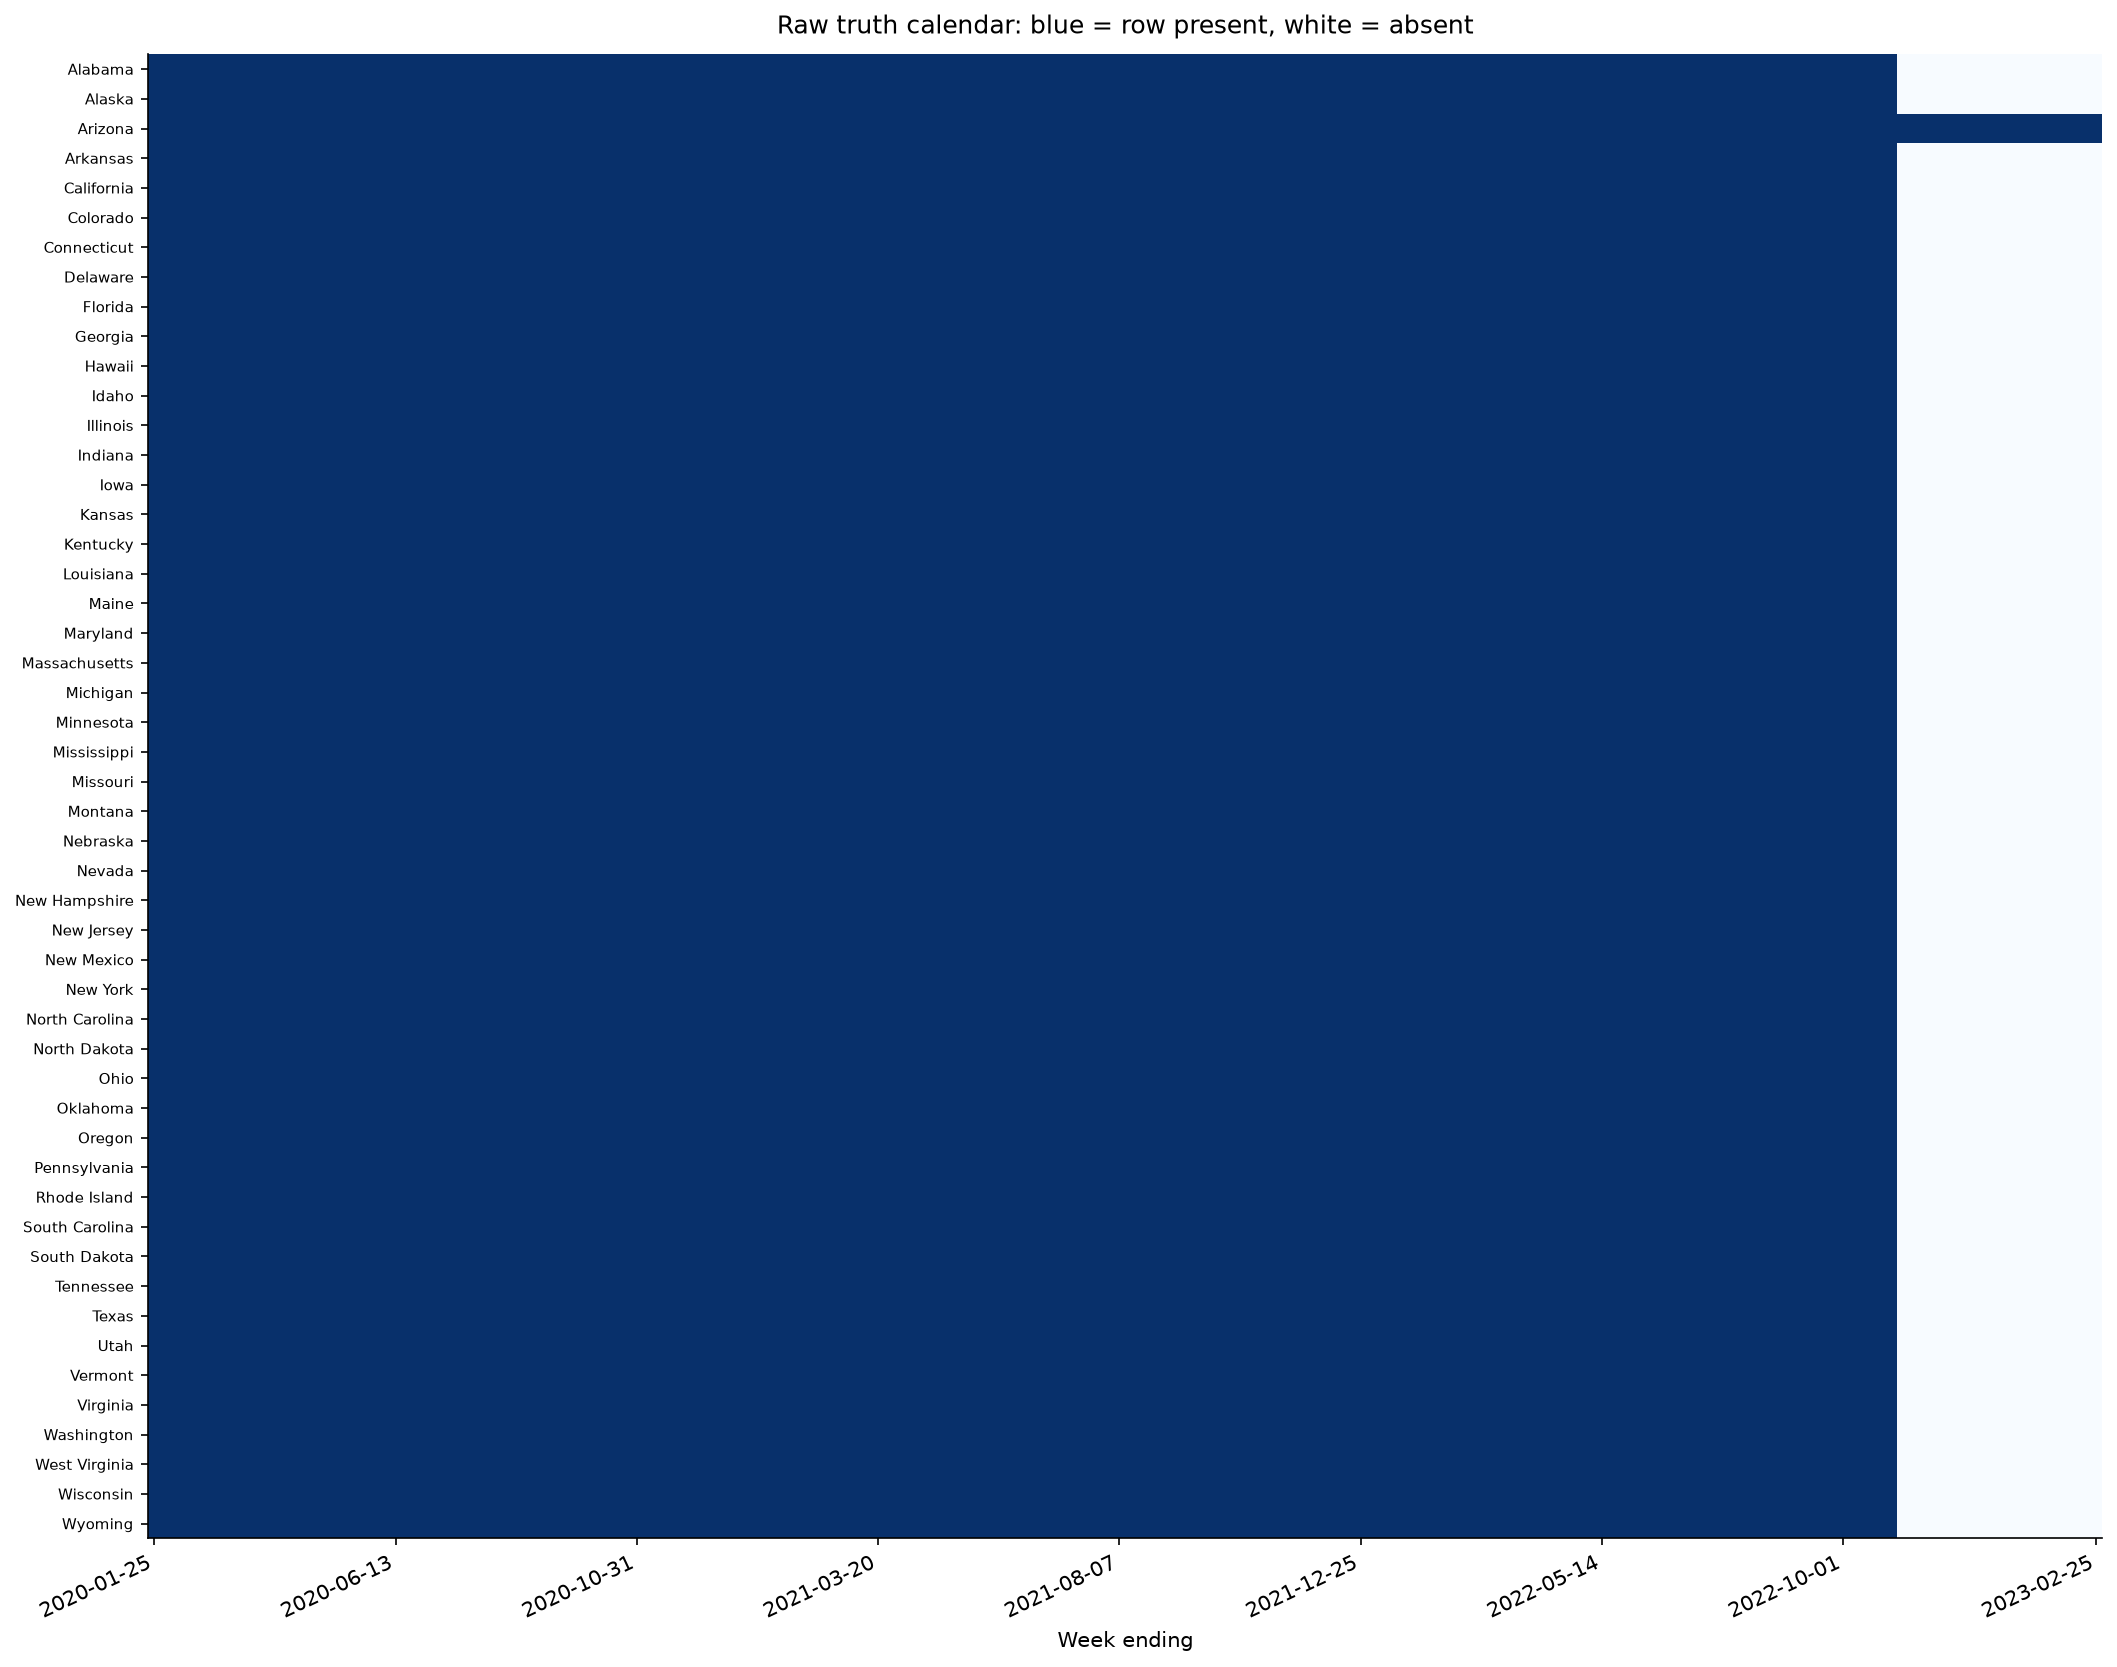

In [9]:
display(Image(filename=str(OUT / "figures/03_truth_calendar.png")))

### Chuỗi số ca raw của bốn bang
Giữ giá trị âm và đánh dấu riêng. Khác biệt magnitude khiến pooled absolute errors có thể bị chi phối bởi bang lớn.

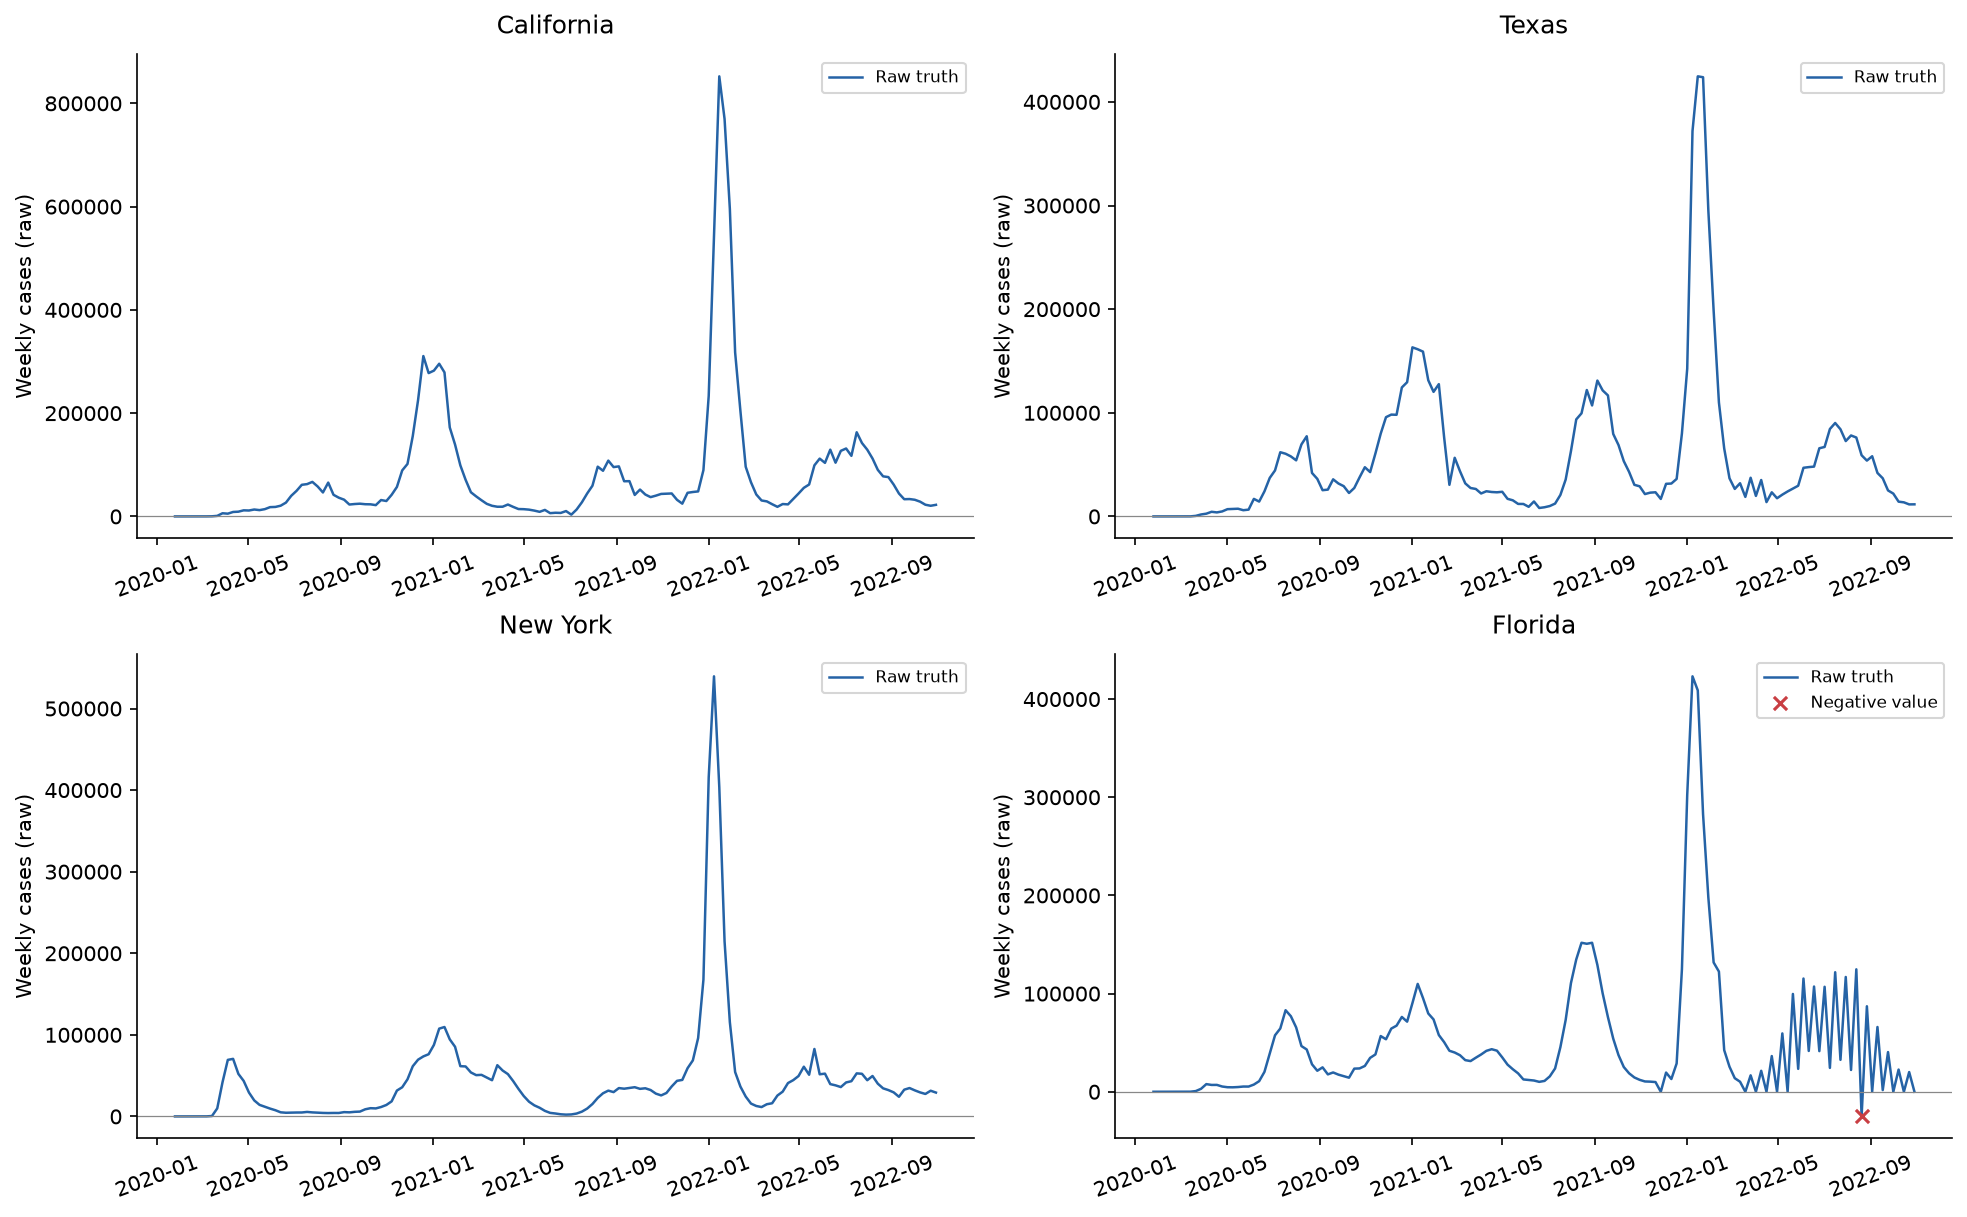

In [10]:
display(Image(filename=str(OUT / "figures/04_truth_examples.png")))

### Quy mô và thời điểm giữa các bang
Panel trái chỉ dùng tuần có mặt ở mọi bang, clip âm về 0 cho hiển thị và chia cho peak mỗi bang trên chính khoảng chung đó; panel phải dùng peak raw theo toàn lịch từng bang.

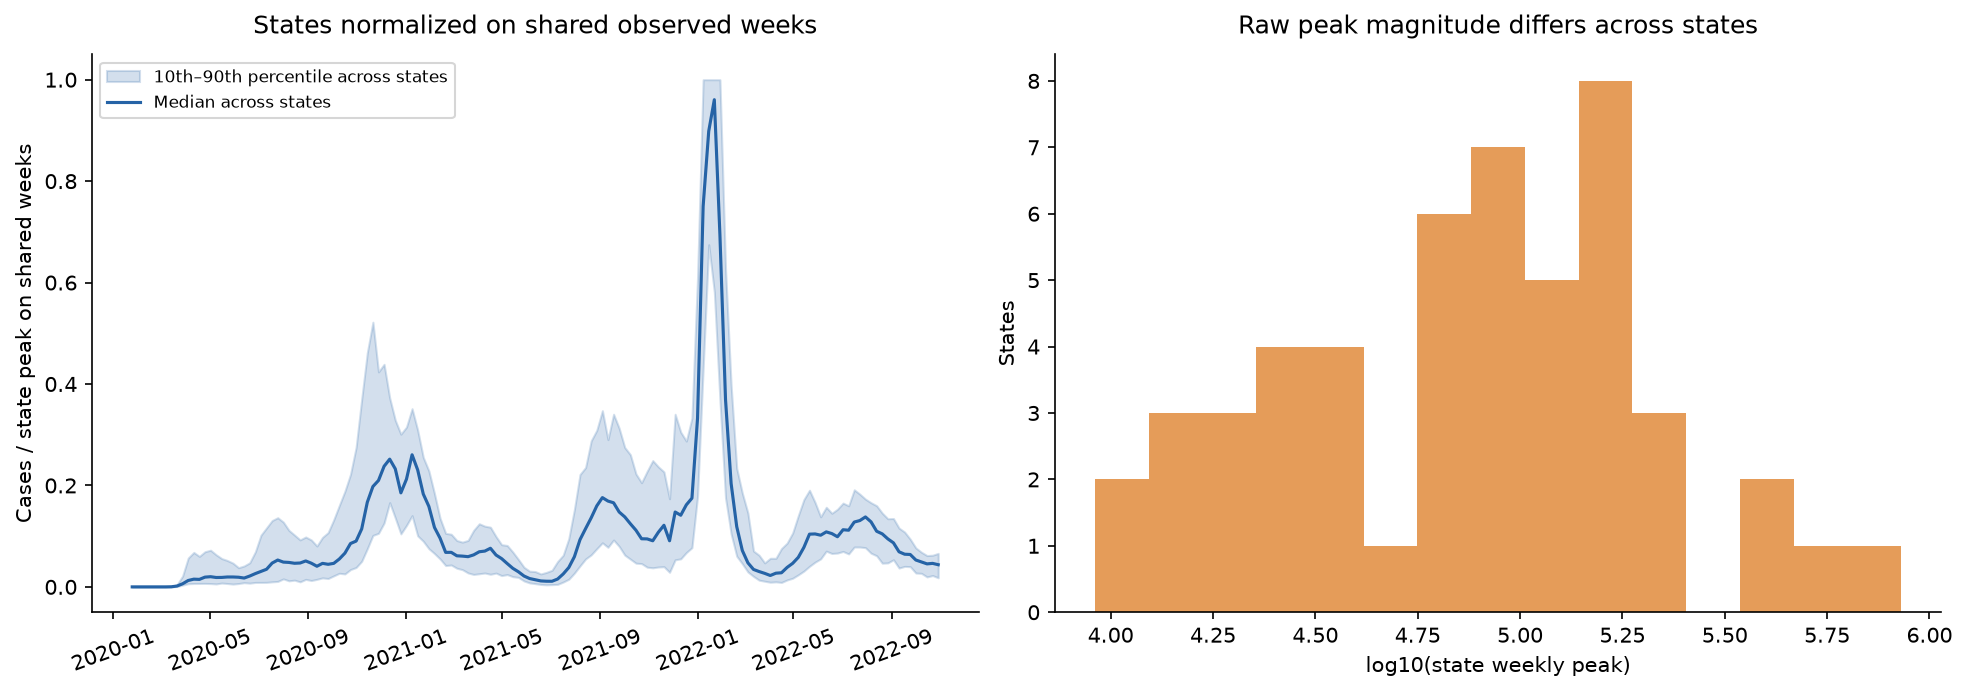

In [11]:
display(Image(filename=str(OUT / "figures/05_truth_scale_and_timing.png")))

## 6. Cách dùng kết quả

- Thư viện nhỏ hiện tại chỉ phục vụ kiểm chứng pipeline; không đại diện cấu hình đầy đủ của bài báo.
- Nhiều floor values tạo cửa sổ phẳng; embedding loại cửa sổ history có variance bằng 0.
- Độ dài/cadence khác nhau làm số cửa sổ mỗi curve khác nhau; chưa tự reweight hay resample.
- Các bang có thể có ngày kết thúc khác nhau: dùng khoảng ngày chung khi benchmark.
- Raw truth có thể có giá trị âm. Ghi rõ khi dùng `--negative-truth clip`; không thay thế bằng dữ liệu as-of.
- Final truth đã có thể được chỉnh sửa sau origin; EDA này chưa chứng minh khả năng dự báo thời gian thực.
- Biểu đồ mô tả full dataset không dùng để tune mô hình hoặc chọn giai đoạn có điểm đẹp.

Báo cáo có thể mở tại `outputs/dataset_exploration/report.md`; các bảng CSV và metadata/checksum ở cùng thư mục.